<a href="https://colab.research.google.com/github/MohamedAamer01/otto-recommender-sys/blob/main/notebooks/02_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 - Exploratory Data Analysis (OTTO)

**Objectif** : tester des hypothèses sur les données avant de modéliser.

| # | Hypothèse | Statut |
|---|---|---|
| H1 | Popularité des articles : longue traîne | à tester |
| H2 | Les 1000 premières sessions étaient atypiques (ordre du fichier) | à tester |
| H3 | L'entonnoir clicks → carts → orders n'est pas systématique | à tester |
| H4 | Le test est tronqué par rapport au train | à tester |

**Résultats de la Phase 1** : 12 899 779 sessions, 216 716 096 événements, 1 855 603 articles, médiane de session = 6.

**Monter le drive**

In [2]:
import os, json, time, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True

N = 216_716_096              # événements (train)
N_SESSIONS = 12_899_779      # sessions (train)
TYPE2ID = {"clicks": 0, "carts": 1, "orders": 2}
ID2TYPE = {v: k for k, v in TYPE2ID.items()}

In [3]:
from google.colab import drive
drive.mount("/content/drive")

NPY_DIR = "/content/drive/MyDrive/OTTO_Recommender_System/data/processed"
os.makedirs(NPY_DIR, exist_ok=True)

names = ["aid", "ts", "type", "sizes"]
npy_ready = all(os.path.exists(f"{NPY_DIR}/{n}.npy") for n in names)
print("Fichiers .npy déjà sur Drive :", npy_ready)
print(os.listdir(NPY_DIR))

Mounted at /content/drive
Fichiers .npy déjà sur Drive : True
['aid.npy', 'ts.npy', 'type.npy', 'sizes.npy']


**authentification Kaggle**

In [4]:
from google.colab import userdata

token = userdata.get("KAGGLE_API_TOKEN")
assert token, "Token introuvable (active l'accès au notebook dans le panneau Secrets)"
os.environ["KAGGLE_API_TOKEN"] = token
print("Kaggle API Token configuré")

Kaggle API Token configuré


**téléchargement**

In [5]:
!pip install -q --upgrade kaggle

DATA_DIR = "/content/otto_data"
os.makedirs(DATA_DIR, exist_ok=True)
!kaggle competitions download -c otto-recommender-system -p /content/otto_data

100% 1.94G/1.94G [01:53<00:00, 18.3MB/s]



Extraction

In [6]:
zip_path = os.path.join(DATA_DIR, "otto-recommender-system.zip")
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(DATA_DIR)

train_path = os.path.join(DATA_DIR, "train.jsonl")
print(os.listdir(DATA_DIR))
print("train.jsonl présent :", os.path.exists(train_path))

['otto-recommender-system.zip', 'train.jsonl', 'sample_submission.csv', 'test.jsonl']
train.jsonl présent : True


# **conversion JSONL → .npy et sauvegarde**

In [7]:
aid_arr   = np.empty(N, dtype=np.int32)
ts_arr    = np.empty(N, dtype=np.int32)    # secondes (ms // 1000)
type_arr  = np.empty(N, dtype=np.int8)     # 0=clicks, 1=carts, 2=orders
sizes_arr = np.empty(N_SESSIONS, dtype=np.int32)

pos = 0
t0 = time.time()
with open(train_path, "r") as f:
    for i, line in enumerate(f):
        evs = json.loads(line)["events"]
        n = len(evs)
        aid_arr[pos:pos+n]  = [e["aid"] for e in evs]
        ts_arr[pos:pos+n]   = [e["ts"] // 1000 for e in evs]
        type_arr[pos:pos+n] = [TYPE2ID[e["type"]] for e in evs]
        sizes_arr[i] = n
        pos += n
        if (i + 1) % 2_000_000 == 0:
            print(f"{i+1:,} sessions ({time.time()-t0:.0f}s)")

assert pos == N and i + 1 == N_SESSIONS, "Conversion incomplète"
print(f"Conversion terminée en {(time.time()-t0)/60:.1f} min")

# Sauvegarde immédiate sur Drive
for name, arr in [("aid", aid_arr), ("ts", ts_arr), ("type", type_arr), ("sizes", sizes_arr)]:
    np.save(f"{NPY_DIR}/{name}.npy", arr)

for fn in sorted(os.listdir(NPY_DIR)):
    print(f"{fn:<12}{os.path.getsize(os.path.join(NPY_DIR, fn))/1e9:.2f} GB")

2,000,000 sessions (113s)
4,000,000 sessions (182s)
6,000,000 sessions (240s)
8,000,000 sessions (288s)
10,000,000 sessions (334s)
12,000,000 sessions (376s)
Conversion terminée en 6.5 min
aid.npy     0.87 GB
sizes.npy   0.05 GB
ts.npy      0.87 GB
type.npy    0.22 GB


a lancer chaque nouvelle session pour chargement de tableaux

In [8]:
t0 = time.time()
aid_arr   = np.load(f"{NPY_DIR}/aid.npy")
ts_arr    = np.load(f"{NPY_DIR}/ts.npy")
type_arr  = np.load(f"{NPY_DIR}/type.npy")
sizes_arr = np.load(f"{NPY_DIR}/sizes.npy")
print(f"Chargé en {time.time()-t0:.0f}s")

Chargé en 11s


**contrôles de cohérence**

In [9]:
assert len(aid_arr) == len(ts_arr) == len(type_arr) == N
assert len(sizes_arr) == N_SESSIONS
assert sizes_arr.sum() == N
assert set(np.unique(type_arr)) == {0, 1, 2}

for name, a in [("aid", aid_arr), ("ts", ts_arr), ("type", type_arr), ("sizes", sizes_arr)]:
    print(f"{name:<6}{str(a.dtype):<8}{a.nbytes/1e9:.2f} GB")
print("Contrôles OK")

aid   int32   0.87 GB
ts    int32   0.87 GB
type  int8    0.22 GB
sizes int32   0.05 GB
Contrôles OK


**vérification visuelle**

In [10]:
sid = np.repeat(np.arange(3, dtype=np.int32), sizes_arr[:3])   # 3 premières sessions seulement
n_show = len(sid)

df_head = pd.DataFrame({
    "session": sid,
    "aid": aid_arr[:n_show],
    "ts": ts_arr[:n_show],
    "type": [ID2TYPE[t] for t in type_arr[:n_show]],
})
display(df_head.head(10))

,session,aid,ts,type
0,0,1517085,1659304800,clicks
1,0,1563459,1659304904,clicks
2,0,1309446,1659367439,clicks
3,0,16246,1659367719,clicks
4,0,1781822,1659367871,clicks
5,0,1152674,1659367885,clicks
6,0,1649869,1659369893,carts
7,0,461689,1659369898,carts
8,0,305831,1659370027,orders
9,0,461689,1659370027,orders


Premiere Analyse H2

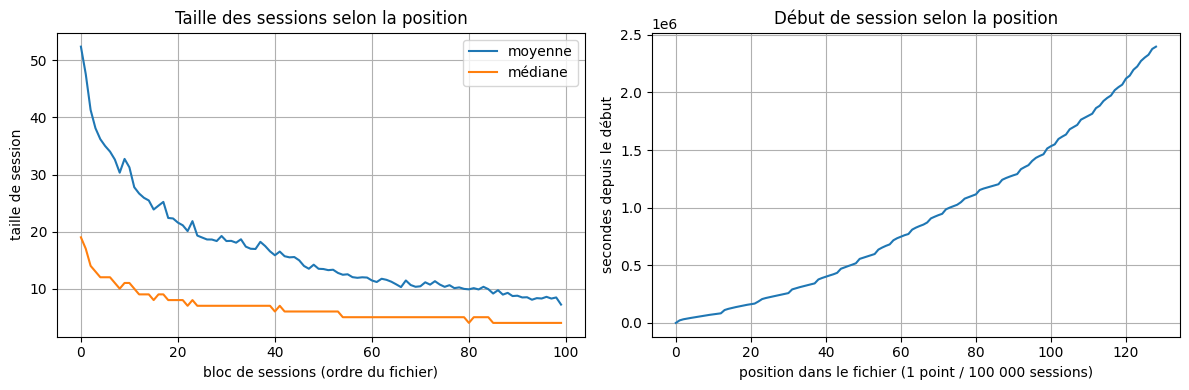

In [11]:
starts = np.concatenate([[0], np.cumsum(sizes_arr, dtype=np.int64)[:-1]])
session_start_ts = ts_arr[starts]

blocks = np.array_split(np.arange(N_SESSIONS), 100)
mean_size   = [sizes_arr[b].mean() for b in blocks]
median_size = [np.median(sizes_arr[b]) for b in blocks]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(mean_size, label="moyenne")
ax[0].plot(median_size, label="médiane")
ax[0].set_xlabel("bloc de sessions (ordre du fichier)")
ax[0].set_ylabel("taille de session")
ax[0].set_title("Taille des sessions selon la position")
ax[0].legend()

ax[1].plot(session_start_ts[::100_000] - session_start_ts[0])
ax[1].set_xlabel("position dans le fichier (1 point / 100 000 sessions)")
ax[1].set_ylabel("secondes depuis le début")
ax[1].set_title("Début de session selon la position")

plt.tight_layout()
plt.show()

In [12]:
import os
for fn in sorted(os.listdir(NPY_DIR)):
    print(f"{fn:<12}{os.path.getsize(os.path.join(NPY_DIR, fn))/1e9:.2f} GB")

aid.npy     0.87 GB
sizes.npy   0.05 GB
ts.npy      0.87 GB
type.npy    0.22 GB


# **Activite dans le temps**

,n_sessions,mean_size,median_size
day,,,
2022-07-31,62777,51.835497,19.0
2022-08-01,1195124,37.398577,13.0
2022-08-02,934413,26.780494,9.0
2022-08-03,837448,22.071320,8.0
2022-08-04,712389,19.084723,7.0
2022-08-05,568595,18.501818,7.0
2022-08-06,514134,17.441488,7.0
2022-08-07,539249,16.774019,7.0
2022-08-08,416588,15.721552,6.0


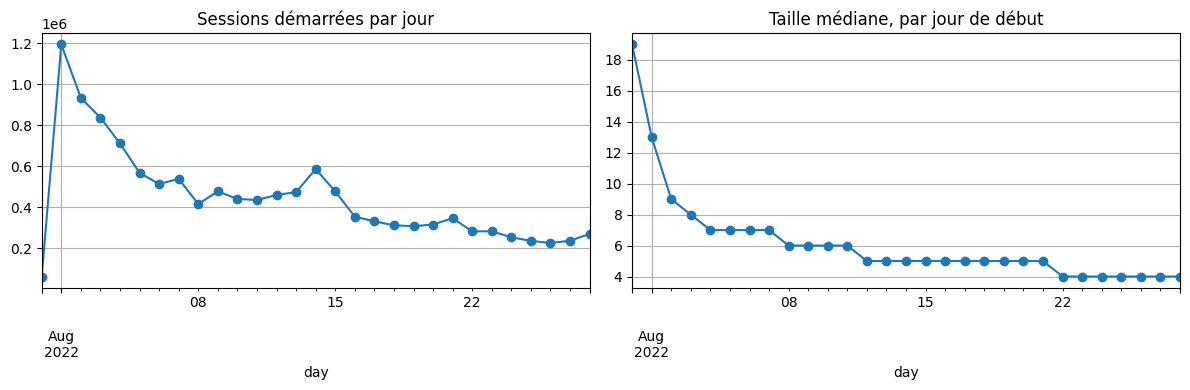

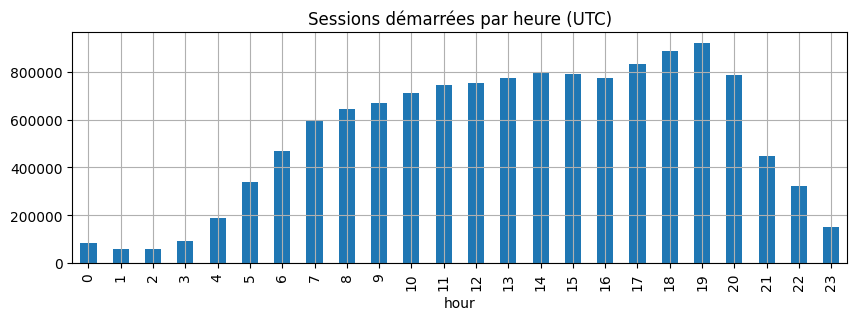

In [13]:
starts_idx = np.concatenate([[0], np.cumsum(sizes_arr, dtype=np.int64)[:-1]])
start_dt = pd.to_datetime(ts_arr[starts_idx], unit="s")

s = pd.DataFrame({"start": start_dt, "size": sizes_arr})
s["day"] = s["start"].dt.floor("D")

daily = s.groupby("day").agg(n_sessions=("size", "size"),
                             mean_size=("size", "mean"),
                             median_size=("size", "median"))
display(daily)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
daily["n_sessions"].plot(ax=ax[0], marker="o", title="Sessions démarrées par jour")
daily["median_size"].plot(ax=ax[1], marker="o", title="Taille médiane, par jour de début")
plt.tight_layout(); plt.show()

s["hour"] = s["start"].dt.hour
s.groupby("hour").size().plot(kind="bar", figsize=(10, 3), title="Sessions démarrées par heure (UTC)")
plt.show()

count    1.289978e+07
mean     1.645941e+02
std      2.024852e+02
min      0.000000e+00
25%      1.452778e-01
50%      5.156056e+01
75%      3.096933e+02
90%      5.077448e+02
99%      6.463062e+02
max      6.719975e+02
Name: duration_h, dtype: float64
Sessions > 24 h    : 54.9 %
Sessions > 7 jours : 37.4 %


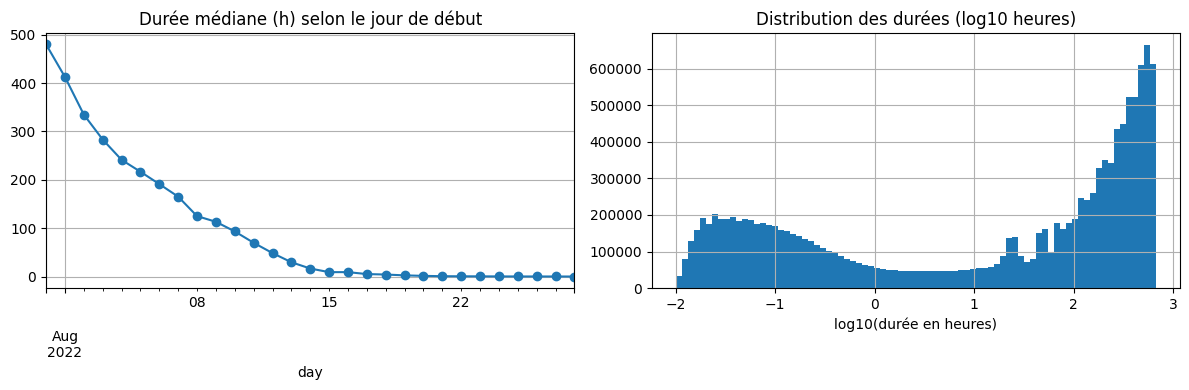

In [14]:
last_idx = starts_idx + sizes_arr - 1
s["duration_h"] = (ts_arr[last_idx].astype(np.int64) - ts_arr[starts_idx]) / 3600

print(s["duration_h"].describe(percentiles=[.25, .5, .75, .9, .99]))
print(f"Sessions > 24 h    : {(s['duration_h'] > 24).mean()*100:.1f} %")
print(f"Sessions > 7 jours : {(s['duration_h'] > 168).mean()*100:.1f} %")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
s.groupby("day")["duration_h"].median().plot(ax=ax[0], marker="o",
    title="Durée médiane (h) selon le jour de début")
ax[1].hist(np.log10(s["duration_h"] + 0.01), bins=80)
ax[1].set_title("Distribution des durées (log10 heures)")
ax[1].set_xlabel("log10(durée en heures)")
plt.tight_layout(); plt.show()

# **popularité des articles (H1)**

Articles : 1855603
Médiane d'événements par article : 20.0
Moyenne : 116.8
Top  0.1% des articles (1,855) -> 13.9 % des événements
Top    1% des articles (18,556) -> 38.2 % des événements
Top   10% des articles (185,560) -> 75.7 % des événements
Top   50% des articles (927,801) -> 95.6 % des événements


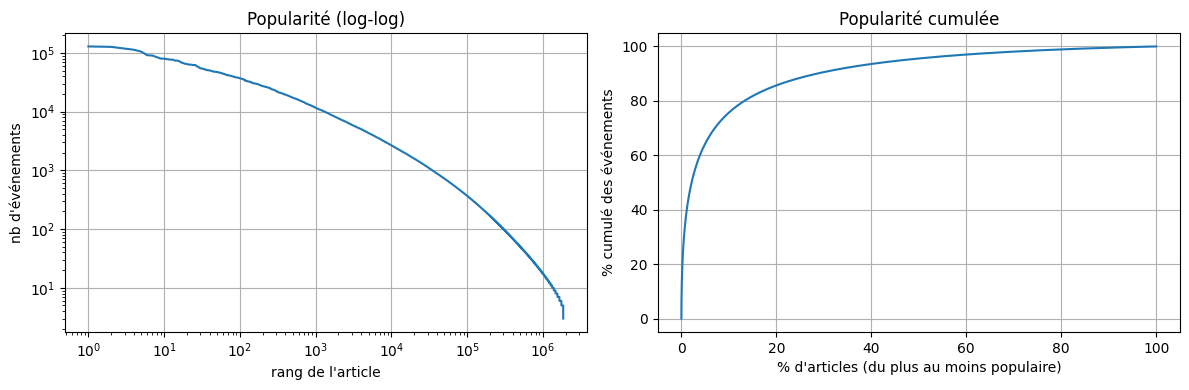

In [15]:
counts = np.bincount(aid_arr)            # counts[aid] = nombre d'événements
counts = counts[counts > 0]              # on retire les aid absents
counts_sorted = np.sort(counts)[::-1]    # du plus populaire au moins populaire

print("Articles :", len(counts_sorted))
print("Médiane d'événements par article :", np.median(counts_sorted))
print("Moyenne :", counts_sorted.mean().round(1))

cum = np.cumsum(counts_sorted) / counts_sorted.sum()
for pct in [0.1, 1, 10, 50]:
    k = int(len(counts_sorted) * pct / 100)
    print(f"Top {pct:>4}% des articles ({k:,}) -> {cum[k-1]*100:.1f} % des événements")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].loglog(np.arange(1, len(counts_sorted)+1), counts_sorted)
ax[0].set_xlabel("rang de l'article"); ax[0].set_ylabel("nb d'événements")
ax[0].set_title("Popularité (log-log)")
ax[1].plot(np.linspace(0, 100, len(cum)), cum * 100)
ax[1].set_xlabel("% d'articles (du plus au moins populaire)")
ax[1].set_ylabel("% cumulé des événements")
ax[1].set_title("Popularité cumulée")
plt.tight_layout(); plt.show()

**Popularité selon le type, et dans le temps**

In [16]:
# Comptages par type
cnt = {t: np.bincount(aid_arr[type_arr == i], minlength=aid_arr.max()+1)
       for t, i in TYPE2ID.items()}

top_k = 20
tops = {t: set(np.argsort(c)[::-1][:top_k]) for t, c in cnt.items()}
print("Recouvrement top-20 clicks/carts :", len(tops["clicks"] & tops["carts"]))
print("Recouvrement top-20 clicks/orders :", len(tops["clicks"] & tops["orders"]))
print("Recouvrement top-20 carts/orders  :", len(tops["carts"] & tops["orders"]))

# Popularité par semaine : le top-20 global reste-t-il en tête ?
week = ((ts_arr - ts_arr.min()) // (7 * 86400)).astype(np.int8)
print("Semaines présentes :", np.unique(week))

top_global = np.argsort(np.bincount(aid_arr))[::-1][:top_k]
for w in np.unique(week):
    mask = week == w
    wc = np.bincount(aid_arr[mask], minlength=aid_arr.max()+1)
    top_w = set(np.argsort(wc)[::-1][:top_k])
    print(f"Semaine {w} : {len(top_w & set(top_global))}/20 en commun avec le top global")

Recouvrement top-20 clicks/carts : 11
Recouvrement top-20 clicks/orders : 7
Recouvrement top-20 carts/orders  : 11
Semaines présentes : [0 1 2 3]
Semaine 0 : 11/20 en commun avec le top global
Semaine 1 : 13/20 en commun avec le top global
Semaine 2 : 13/20 en commun avec le top global
Semaine 3 : 11/20 en commun avec le top global


**H3, l'entonnoir clicks → carts → orders**

In [17]:
def funnel_stats(n_blocks=100):
    stats = dict(orders=0, orders_with_cart=0, orders_with_click=0,
                 orders_with_either=0, carts=0, carts_with_click=0)
    bounds = np.array_split(np.arange(N_SESSIONS), n_blocks)
    cum = np.concatenate([[0], np.cumsum(sizes_arr, dtype=np.int64)])

    for b in bounds:
        a, z = b[0], b[-1] + 1
        s, e = cum[a], cum[z]
        sid = np.repeat(np.arange(z - a, dtype=np.int64), sizes_arr[a:z])
        key = (sid << 21) | aid_arr[s:e].astype(np.int64)
        t = type_arr[s:e]

        k_click, k_cart, k_order = key[t == 0], key[t == 1], key[t == 2]

        in_cart  = np.isin(k_order, k_cart)
        in_click = np.isin(k_order, k_click)
        stats["orders"]            += len(k_order)
        stats["orders_with_cart"]  += in_cart.sum()
        stats["orders_with_click"] += in_click.sum()
        stats["orders_with_either"]+= (in_cart | in_click).sum()
        stats["carts"]             += len(k_cart)
        stats["carts_with_click"]  += np.isin(k_cart, k_click).sum()
    return stats

t0 = time.time()
st = funnel_stats()
print(f"Durée : {time.time()-t0:.0f}s")
for k, v in st.items():
    print(f"{k:<20}{v:>12,}")
print(f"\nOrders avec cart du même aid dans la session  : {st['orders_with_cart']/st['orders']*100:.1f} %")
print(f"Orders avec click du même aid dans la session : {st['orders_with_click']/st['orders']*100:.1f} %")
print(f"Orders avec cart OU click                     : {st['orders_with_either']/st['orders']*100:.1f} %")
print(f"Carts avec click du même aid                  : {st['carts_with_click']/st['carts']*100:.1f} %")

Durée : 168s
orders                 5,098,951
orders_with_cart       4,690,249
orders_with_click      4,336,749
orders_with_either     4,875,940
carts                 16,896,191
carts_with_click      15,114,602

Orders avec cart du même aid dans la session  : 92.0 %
Orders avec click du même aid dans la session : 85.1 %
Orders avec cart OU click                     : 95.6 %
Carts avec click du même aid                  : 89.5 %
